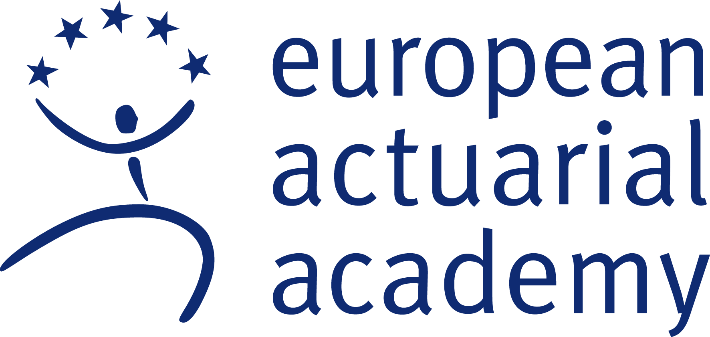

<p style="font-size:17px; text-align:left;"><i>EAA Web Session E0595, GenAI Beyond the Basics: Advanced Concepts for Actuaries, 07 December 2026</i></p>
<p style="font-size:25px; text-align:left; font-weight:bold;">Notebook 3: Function Calling, Letting the Model Use Your Code and Data</p>
<p style="font-size:16px; text-align:left; margin-bottom: 15px;">Dr Simon Hatzesberger<br>Programme slot: 10:05–10:25 CET</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/genai-beyond-the-basics-20261207/blob/main/notebooks/03_function_calling.ipynb) &nbsp; Notebook `03_function_calling.ipynb` of the repository <https://github.com/simonhatzesberger/genai-beyond-the-basics-20261207>

LLMs understand requests and write text, but they should not *invent* numbers. **Function Calling** lets a model ask
your application to run a predefined function, for example a database query or a calculation, and use the result in
its answer. The use case retrieves mortality probabilities from an SQLite database of German private health insurance
mortality tables.

**Contents**
1. [Concept and purpose](#function-calling-concept)
2. [Setup](#setup)
3. [Use case: mortality data retrieval from a database](#function-calling-usecase)
4. [Further applications and resources](#function-calling-further-applications-and-resources)

<h1 id="function-calling-concept"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
1. Concept and Purpose
</h1>

LLMs excel at understanding and generating natural-language text, but they **cannot execute deterministic business logic**—such as database look-ups, actuarial calculations, or API calls—on their own. *Function Calling* (sometimes called *Tool Calling*) solves this by allowing you to expose a controlled set of back-end functions to the model. The LLM can then decide, at generation time, whether to:

* answer the user directly, or  
* request that the application run one of the provided functions and feed the result back into the conversation.

This pattern combines the creativity and intent-recognition skills of the LLM with the reliability, speed, and auditability of classical code.

<div style="background-color: #f2f2f2; border-left: 4px solid #888888; padding-left: 10px; padding-bottom: 1px; padding-top: 6px;">
<p style="font-weight: bold"><b>Note</b></p>
<p style="margin-bottom: 10px;">

A limitation of <em>Function Calling</em> is that the LLM can only invoke functions that have been explicitly defined and exposed in advance. Agentic AI (notebook 06) extends this approach: the model calls tools in a loop until a goal is reached, and some agents can even write and run new code in a sandbox, which requires correspondingly stronger guardrails.

</p>
</div>

#### Why It Matters for Actuaries

* **Repeatability & Compliance** – deterministic functions ensure that premium calculations, reserving routines, or regulatory checks are performed exactly the same way every time.  
* **Traceability** – every function invocation, its arguments, and its result are logged, producing an audit trail that satisfies governance requirements.  
* **Scalability** – once wrapped as callable tools, anything from a simple NPV formula to a high-performance risk engine can be orchestrated by the model.  
* **Lower prompting effort** – instead of forcing the model to produce long, perfectly formatted answers, you let code do the heavy lifting and let the LLM focus on *deciding* **what** to call and *explaining* **why**.

#### How Function Calling Works  

The interaction – illustrated in the diagram below – can be described by the following six steps:

1. **Application → LLM**  
   Send the user prompt together with JSON definitions of the available functions.  
2. **LLM reasoning**  
   Decide whether to respond directly or to invoke one or more tools (e.g., functions); if tools are needed, generate the arguments.  
3. **LLM → Application**  
   Return either a normal assistant message or a special message that contains the chosen `function_name` and `arguments`.  
4. **Application layer**  
   Parse the message and execute the requested function(s) with the supplied arguments.  
5. **Application → LLM**  
   Call the LLM again, passing both the original prompt (to preserve context) and the **result** of the function call.  
6. **LLM reasoning and (possibly) final response**  
   Use the new information to formulate a final answer or trigger additional tool calls, repeating steps 2–5 as needed.

<center>
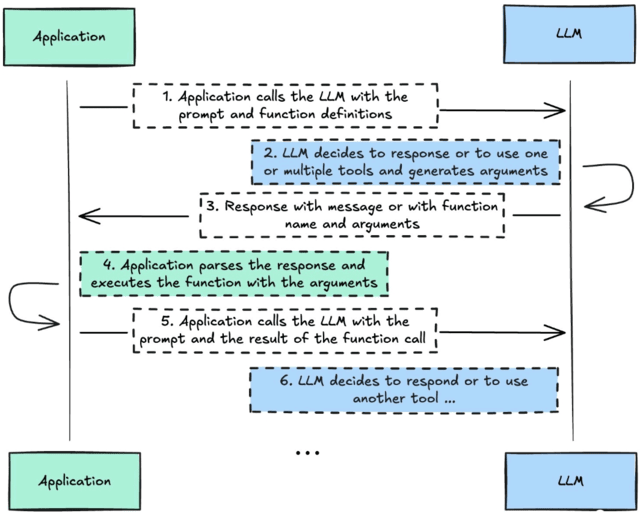
<br>
<i>Schematic illustration of the individual stages of Function Calling.</i><br>
<i>[Source: https://ai.plainenglish.io/a-brief-introduction-to-retrieval-augmented-generation-rag-b7eb70982891]</i>
</center>

Since the LLM does not execute code directly, every calculation or data access goes through a sandbox that **you** control. You decide which functions are exposed and which arguments are valid – an important safety feature when handling sensitive policy or claims data.

<h1 id="setup"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
2. Setup
</h1>

In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────────────────────
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/genai-beyond-the-basics-20261207/main/notebooks/"

import json
import sqlite3
from openai import OpenAI


def load_openai_api_key(name: str = "OPENAI_API_KEY", file_path: str = "openai_api_key.txt") -> str | None:
    """Look for the key in Colab Secrets, then in an environment variable, then in a local text file."""
    try:
        from google.colab import userdata  # only available in Colab
        value = userdata.get(name)
        if value:
            return value.strip()
    except Exception:
        pass
    if os.getenv(name):
        return os.getenv(name).strip()
    for candidate in (Path(file_path), Path("..") / file_path):
        if candidate.exists():
            return candidate.read_text(encoding="utf-8").strip()
    return None


api_key = load_openai_api_key()
client = OpenAI(api_key=api_key or "no-key-found")   # the key's value is never printed

MODEL = "gpt-6-luna"           # OpenAI's current small model (checked 22 Nov 2026: no announced shutdown date)
REASONING = {"effort": "low"}  # always set the reasoning effort explicitly (the default is "medium")


def data_file(name: str) -> Path:
    """A data file of this notebook: from data/ next to it, otherwise downloaded once from GitHub (e.g. in Colab)."""
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + "data/" + name, path)
        print(f"Downloaded data/{name} from GitHub.")
    return path

print("Running in", "Google Colab" if IN_COLAB else "a local Python " + sys.version.split()[0])
print("OpenAI API key:", "found" if api_key else "NOT found - you can read the saved outputs, but API calls will fail "
      "(see 00_setup_check.ipynb)")
print("Model:", MODEL, "| reasoning effort:", REASONING["effort"])

Running in a local Python 3.13.1
OpenAI API key: found
Model: gpt-6-luna | reasoning effort: low


<h1 id="function-calling-usecase"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
3. Use Case: Mortality Data Retrieval from a Database via Function Calling
</h1>

In this use case, we show how Function Calling lets an LLM delegate deterministic data retrieval – here, fetching mortality probabilities for men aged 85–100 from an SQLite database – to a Python helper function, then focus on analysis and explanation. This ensures that data access is exact and auditable, while the model handles orchestration and narrative.

The database `data/mortality_tables.sqlite` holds the **PKV-Sterbetafeln 2022 to 2025**, the mortality tables for
German private health insurance published by BaFin: one table `mortality_table` with the columns `mortality_table`,
`gender`, `age` and `probability` (the one-year death probability $q_x$), for ages 0 to 102.

**Step 1: Application → LLM**

_We define the Python function `fetch_probabilities`, describe it and its parameters in a JSON schema, register it in
`tools`, and send the user's request together with the tool definitions._

Two details make the function safe to expose: the database is opened **read-only**, and the user's values are passed
as **SQL parameters** (`?`), never pasted into the SQL text, so a malicious argument cannot change the query.

In [2]:
DB_PATH = data_file("mortality_tables.sqlite")


def fetch_probabilities(mortality_table: str, start_age: int, end_age: int, sex: str = "FEMALE") -> list[dict]:
    """Return [{"age": x, "probability": q_x}, ...] for ages start_age..end_age of one table and sex."""
    with sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True) as conn:   # read-only
        rows = conn.execute(
            """SELECT age, probability FROM mortality_table
               WHERE mortality_table = ? AND gender = ? AND age BETWEEN ? AND ?
               ORDER BY age""",
            (mortality_table, sex.upper(), int(start_age), int(end_age)),
        ).fetchall()
    return [{"age": age, "probability": prob} for age, prob in rows]


# Describe the function for the model: name, purpose and a JSON schema of its parameters
tools = [
    {
        "type": "function",
        "name": "fetch_probabilities",
        "description": "Fetch one-year mortality probabilities q_x from the database of German PKV mortality tables.",
        "parameters": {
            "type": "object",
            "properties": {
                "mortality_table": {
                    "type": "string",
                    "description": "Name of the mortality table, e.g. 'PKV-Sterbetafel 2025' (available: 2022 to 2025)",
                },
                "start_age": {"type": "integer", "description": "Start age (inclusive)"},
                "end_age": {"type": "integer", "description": "End age (inclusive)"},
                "sex": {"type": "string", "enum": ["MALE", "FEMALE"], "description": "Sex"},
            },
            "required": ["mortality_table", "start_age", "end_age", "sex"],
            "additionalProperties": False,
        },
        "strict": True,
    }
]

# Compose the user request
user_prompt = (
    'Please fetch the probabilities for men between age 85 and 85 plus 10 from the mortality table '
    '"PKV-Sterbetafel 2025". First, present the data in a markdown table with columns "Age" and "Probability". '
    'Then analyse the progression: is it increasing, decreasing or irregular? Close with a one-sentence '
    'actuarial interpretation.'
)
input_messages = [{"role": "user", "content": user_prompt}]

# Send the request together with the tool definitions
response = client.responses.create(model=MODEL, reasoning=REASONING, input=input_messages, tools=tools)

**Step 2: LLM reasoning**

_The model decides whether to call `fetch_probabilities` or to answer directly. We check its decision._

In [3]:
calls = [item for item in response.output if item.type == "function_call"]
if calls:
    print(f"The model decided to call: {calls[0].name}")
else:
    print("The model answered directly:", response.output_text)

The model decided to call: fetch_probabilities


**Step 3: LLM → Application**

_The model returns a `function_call` item with the function name and its arguments as JSON. Note how the model
translated "85 plus 10" and "men" into `end_age=95` and `sex="MALE"`._

In [4]:
tool_call = calls[0]                     # contains name, call_id and arguments
args = json.loads(tool_call.arguments)   # parse the JSON arguments
print("Invoking:", tool_call.name, "with", args)

Invoking: fetch_probabilities with {'mortality_table': 'PKV-Sterbetafel 2025', 'start_age': 85, 'end_age': 95, 'sex': 'MALE'}


**Step 4: Application layer**

_Our code, not the model, executes the function with the generated arguments. This is the point where you validate
arguments, enforce permissions and log the call._

In [5]:
fn_result = fetch_probabilities(**args)
fn_result

[{'age': 85, 'probability': 0.06308},
 {'age': 86, 'probability': 0.07318},
 {'age': 87, 'probability': 0.084803},
 {'age': 88, 'probability': 0.098028},
 {'age': 89, 'probability': 0.112913},
 {'age': 90, 'probability': 0.129465},
 {'age': 91, 'probability': 0.147647},
 {'age': 92, 'probability': 0.167363},
 {'age': 93, 'probability': 0.188107},
 {'age': 94, 'probability': 0.209873},
 {'age': 95, 'probability': 0.232032}]

**Step 5: Application → LLM**

_We append the model's function call and our function's output to the conversation and call the model again, so it
can integrate the results._

In [6]:
input_messages += response.output        # the model's turn, including its function call
input_messages.append({
    "type": "function_call_output",
    "call_id": tool_call.call_id,
    "output": json.dumps(fn_result),
})

response_2 = client.responses.create(model=MODEL, reasoning=REASONING, input=input_messages, tools=tools)

**Step 6: LLM reasoning and final response**

_The model now writes the table and the analysis from the data our function returned._

In [7]:
from IPython.display import Markdown, display
display(Markdown(response_2.output_text))

| Age | Probability |
|---:|---:|
| 85 | 0.06308 |
| 86 | 0.07318 |
| 87 | 0.084803 |
| 88 | 0.098028 |
| 89 | 0.112913 |
| 90 | 0.129465 |
| 91 | 0.147647 |
| 92 | 0.167363 |
| 93 | 0.188107 |
| 94 | 0.209873 |
| 95 | 0.232032 |

The probabilities increase at every age, so the progression is **increasing**. Actuarially, this indicates that the table’s one-year mortality risk for men rises steadily from age 85 through 95.

#### Checking every number

Since the data came from our function, we can verify that every probability in the model's table is exactly a value
from the database, which is a check that costs nothing and catches transcription errors.

In [8]:
import re

db_values = {f"{row['probability']:.6f}".rstrip("0") for row in fn_result}
quoted = set(v.rstrip("0") for v in re.findall(r"0\.\d{3,}", response_2.output_text))
print(f"{len(quoted)} probabilities quoted by the model; not found in the database: {sorted(quoted - db_values) or 'none'}")

11 probabilities quoted by the model; not found in the database: none


#### When the data does not exist

A table for 2030 is not in the database. The function returns an empty list, and a well-instructed model should say
so rather than fill the gap from memory. Handling "no data" explicitly is part of designing a tool.

In [9]:
def ask_with_tools(question: str) -> str:
    """One complete function-calling round trip (steps 1 to 6) for any question."""
    messages = [{"role": "user", "content": question}]
    first = client.responses.create(
        model=MODEL, reasoning=REASONING, input=messages, tools=tools,
        instructions="Answer only from tool results. If a tool returns no data, say so; never estimate missing values.",
    )
    messages += first.output
    for call in (i for i in first.output if i.type == "function_call"):
        result = fetch_probabilities(**json.loads(call.arguments))
        print(f"  [tool] {call.name}({call.arguments}) -> {len(result)} rows")
        messages.append({"type": "function_call_output", "call_id": call.call_id, "output": json.dumps(result)})
    final = client.responses.create(
        model=MODEL, reasoning=REASONING, input=messages, tools=tools,
        instructions="Answer only from tool results. If a tool returns no data, say so; never estimate missing values.",
    )
    return final.output_text

print(ask_with_tools("What is q_70 for women in the PKV-Sterbetafel 2030?"))

  [tool] fetch_probabilities({"mortality_table":"PKV-Sterbetafel 2030","start_age":70,"end_age":70,"sex":"FEMALE"}) -> 0 rows


No data was returned for q₇₀ for women in the PKV-Sterbetafel 2030.


<h1 id="function-calling-further-applications-and-resources"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
4. Further Applications and Resources
</h1>

#### Additional Actuarial Applications for Function Calling

* **Dynamic Tariff Calculation** – Business users adjust inputs such as coverage limits, deductibles, and risk loadings in chat; the LLM invokes a tariff-calculation function to instantly recalculate quotes, making it easy for non-technical staff to explore “what-if” scenarios.  
* **Customer Service with Live Data** – Policyholders ask about their renewal dates, payment history, or coverage details; the model triggers API calls to retrieve up-to-date information and presents it in a clear, conversational format.  
* **Risk Scenario Simulation** – Risk managers describe stress-test parameters in natural language; the LLM calls a simulation engine function to run Monte Carlo scenarios and returns summarized KPIs and distribution charts.  
* **Automated Policy Issuance** – A non-technical underwriter describes client details in plain language; the model calls a policy-generation function that computes premiums, applies endorsements, and returns a ready-to-issue document without any manual coding.  

#### Further Reading and Resources on Function Calling

1. [Function calling — OpenAI API Guide](https://developers.openai.com/api/docs/guides/function-calling)
    * *Type:* Official Documentation
    * *Summary:* The current Responses-API tool schema (`name`/`parameters`/`strict`), `function_call` output items, and how to submit `function_call_output` back to the model.
2. [Migrate to the Responses API — OpenAI API Guide](https://developers.openai.com/api/docs/guides/migrate-to-responses)
    * *Type:* Official Documentation
    * *Summary:* Why the Responses API is recommended for new projects and how the tool-calling shape changed from Chat Completions.
3. [Structured Outputs — OpenAI API Guide](https://developers.openai.com/api/docs/guides/structured-outputs)
    * *Type:* Official Documentation
    * *Summary:* Pairs naturally with function calling to guarantee well-typed tool arguments and responses.